# WP2: Artificial Lagrange points

## Personal problem specification 

| Parameter | Value |
|-----------|-------|
| Sun/Earth Lagrange point | L2 |
| Sun/Mars Lagrange point | L2 |
| Shift in Lagrange points | 0.00100 |
| Radius Martian parking orbit | 244,444 km |
| Lightness number | 0.0300 |

## Library & constant imports

In [1]:
from constants import *

# import numpy as np
# import scipy 
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch
import pickle
import nbimporter
from IPython.display import display

## Task 2.1a 

We now want to equip the spacecraft with a solar sail; this will allow a shift in the location of the Lagrange points. Assume we want to shift both Lagrange points found in Task 1.1a by a certain amount; and we want this shift to occur along the line connecting the Sun and the Lagrange point *in the direction of the Sun*. The amount by which the Lagrange points shall be shifted can be found *in your personal problem specification*.

Compute the required solar-sail performance, i.e., the solar-sail lightness number, to achieve this shift. Assume an ideal performance of the sail

Loading the values from the previous computation:

In [2]:
with open('lagrange_points.pkl', 'rb') as f:
    lagrange_points = pickle.load(f)

L2_earth = lagrange_points['L2_earth']
L2_mars  = lagrange_points['L2_mars']

Conversion of the points into the artificial lagrance points by the shift specified.

In [3]:
L2_artificial_earth = L2_earth + shift_L2
L2_artificial_mars  = L2_mars  + shift_L2

Due to the potential being non-dependant on $y$, $\nabla U$ is collinear with the Sun-Earth line. Hence, the expression for calculating the solar sail orientation ($\mathbf{\hat{n}} = \frac{\nabla U}{|\nabla U|}$) trivially yields $\mathbf{\hat{n}} \parallel x$. 
Hence, the equation provided in the slides to calculate the solar-sail lightness number simplifies as it follows:

$$\beta = \frac{r_1^2}{1 - \mu} \frac{\nabla U \cdot \mathbf{\hat{n}}}{( \mathbf{\hat{r}_1} \cdot \mathbf{\hat{n}})^2} \xRightarrow{\mathbf{\hat{n}} \parallel \mathbf{\hat{r}_1}} \beta = \frac{1}{1 - \mu} \frac{dU}{dx}$$

So, for the Sun-Earth system it yields:

In [4]:
from wp1 import dUdx_colinear

beta_earth = dUdx_colinear(L2_artificial_earth, mass_ratio_sun_earth) / (1 - mass_ratio_sun_earth)
print(f"Solar-sail lightness number at artificial Sun-Earth L2: {beta_earth:.5f}")

Solar-sail lightness number at artificial Sun-Earth L2: 0.00810


And for the Sun-Mars system:

In [5]:
beta_mars = dUdx_colinear(L2_artificial_mars, mass_ratio_sun_mars) / (1 - mass_ratio_sun_mars)
print(f"Solar-sail lightness number at artificial Sun-Mars L2: {beta_mars:.5f}")

Solar-sail lightness number at artificial Sun-Mars L2: 0.00748


### Calculating the solar sail lightness area from sources

The solar-sail lightness number $\beta$ is related to the area-to-mass ratio by:

$$\beta = \frac{2 P r^2}{\mu_\odot} \cdot \frac{A}{m} = \frac{2 P_0 r_0^2}{\mu_\odot} \cdot \frac{A}{m}$$

where:
- $P_0$ is the solar radiation pressure at reference distance $r_0=1 \text{AU}$, equal to $4.5 \mu\text{N/m}^2$ as per the course slides
- $\mu_\odot$ is the solar gravitational parameter
- $A/m$ is the area-to-mass ratio of the sail

In [6]:
P_0 = 4.5e-6 # N/m^2
def lightness_number_to_area_per_mass(area, mass):
    return  2* P_0 * (AU*1e3)**2/ (mu_sun*1e9) * (area / mass)

Parameters for certain missions (from [Ancona and Kezerashvili, 2024](https://arxiv.org/pdf/2411.12492)):

In [7]:
mission = ["Cosmos-1", "NanoSail-D1", "IKAROS", "NanoSail-D2", "LightSail 1", "LightSail 2", "NEA Scout", "GAMA Alpha", "ACS3"]
year = [2005, 2008, 2010, 2011, 2015, 2019, 2022, 2023, 2024]
mass = [100, 4, 315, 4, 5, 5, 14, 12, 16] # kg
surface_area = [600, 10, 200, 10, 32, 32, 86, 73, 80] # m^2
status = ['F', 'F', 'S', 'S', 'S', 'S', 'F', 'S', 'S']  # F: Failed, S: Success

Calculation of the lightness number

In [8]:
beta_values = []
for m, a in zip(mass, surface_area):
    beta = lightness_number_to_area_per_mass(a, m)
    print(f"Mission {mission[len(beta_values)]} ({year[len(beta_values)]}) lightness number: {beta:.5f}")
    beta_values.append(beta)

Mission Cosmos-1 (2005) lightness number: 0.00911
Mission NanoSail-D1 (2008) lightness number: 0.00379
Mission IKAROS (2010) lightness number: 0.00096
Mission NanoSail-D2 (2011) lightness number: 0.00379
Mission LightSail 1 (2015) lightness number: 0.00971
Mission LightSail 2 (2019) lightness number: 0.00971
Mission NEA Scout (2022) lightness number: 0.00932
Mission GAMA Alpha (2023) lightness number: 0.00923
Mission ACS3 (2024) lightness number: 0.00759


Plotting of the lightness number vs the launch year:

Figure saved to figures/solar_sail_lightness_number.pdf


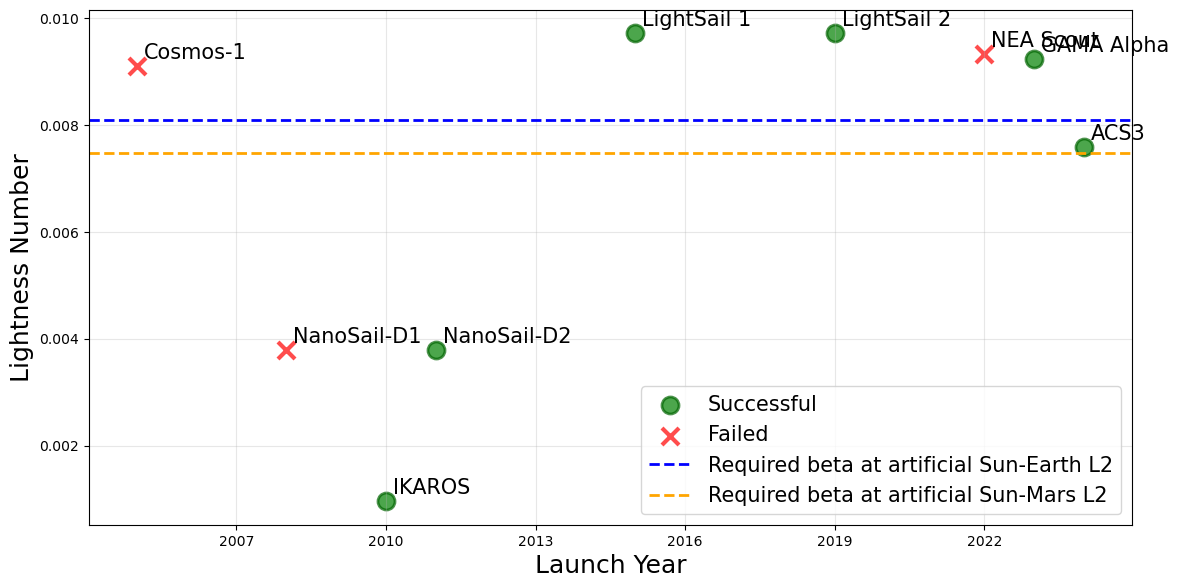

In [9]:
import os

# Create figures directory if it doesn't exist
figures_dir = 'figures'
if not os.path.exists(figures_dir):
    os.makedirs(figures_dir)

plt.figure(figsize=(12, 6))

# Separate missions by status
success_indices = [i for i in range(len(status)) if status[i] == 'S']
fail_indices = [i for i in range(len(status)) if status[i] == 'F']

# Plot successful missions with circles
success_years = [year[i] for i in success_indices]
success_betas = [beta_values[i] for i in success_indices]
plt.scatter(success_years, success_betas, s=150, color='green', alpha=0.7, marker='o', label='Successful', edgecolors='darkgreen', linewidth=2)

# Plot failed missions with X markers
fail_years = [year[i] for i in fail_indices]
fail_betas = [beta_values[i] for i in fail_indices]
plt.scatter(fail_years, fail_betas, s=150, color='red', alpha=0.7, marker='x', linewidth=3, label='Failed')

# Add mission name labels to each point
for i, mission_name in enumerate(mission):
    plt.annotate(mission_name, (year[i], beta_values[i]), 
                xytext=(5, 5), textcoords='offset points', fontsize=15)

# Add horizontal lines for artificial Lagrange points
plt.axhline(y=beta_earth, color='blue', linestyle='--', linewidth=2, label=f'Required beta at artificial Sun-Earth L2')
plt.axhline(y=beta_mars, color='orange', linestyle='--', linewidth=2, label=f'Required beta at artificial Sun-Mars L2')

plt.xlabel('Launch Year', fontsize=18)
plt.ylabel('Lightness Number', fontsize=18)
# plt.title('Solar Sail Lightness Number vs Launch Year', fontsize=14)
plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))
plt.grid(True, alpha=0.3)
plt.legend(fontsize=15, loc='best')
plt.tight_layout()

# Save figure as PDF
pdf_path = os.path.join(figures_dir, 'solar_sail_lightness_number.pdf')
plt.savefig(pdf_path, format='pdf', dpi=300, bbox_inches='tight')
print(f"Figure saved to {pdf_path}")

plt.show()

## Task 2.1b 

Schematic for the acceleration vectors in the solar-sail augmented CR3BP

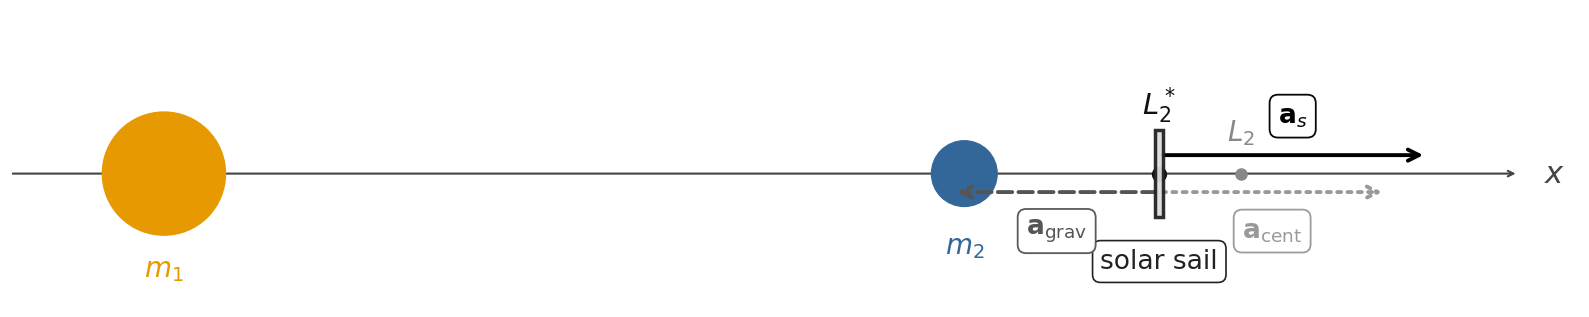

In [10]:
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch

# ── greyscale-safe palette (distinct in both colour and lightness) ─────────────
# a_s:    solid black        (greyscale: ~0.0)
# a_grav: dark grey          (greyscale: ~0.35)
# a_cent: medium grey        (greyscale: ~0.55)  + dashed line to distinguish
# sail:   light grey fill    (greyscale: ~0.85)
C_AS    = '#000000'   # black
C_GRAV  = '#555555'   # dark grey
C_CENT  = '#999999'   # medium grey
C_SAIL_E = '#222222'  # sail edge
C_SAIL_F = '#DDDDDD'  # sail fill
C_SUN   = '#E69900'   # amber  (prints mid-grey)
C_PLAN  = '#336699'   # steel blue (prints dark-grey)
C_AXIS  = '#444444'
C_L2N   = '#888888'
C_L2A   = '#111111'

FS      = 20   # base font size
FS_LBL  = 19   # vector label font size
LW_VEC  = 2.8  # arrow line width
MS_VEC  = 20   # arrowhead scale

fig, ax = plt.subplots(figsize=(16, 5))
ax.set_aspect('equal')
ax.axis('off')

# ── positions ─────────────────────────────────────────────────────────────────
x_sun    = -6.0
x_planet =  1.8
x_L2     =  4.5
x_L2art  =  3.7
y0       =  0.0

# ── x-axis ────────────────────────────────────────────────────────────────────
ax.annotate('', xy=(7.2, 0), xytext=(-7.5, 0),
            arrowprops=dict(arrowstyle='->', color=C_AXIS, lw=1.5))
ax.text(7.45, 0, r'$x$', fontsize=FS+2, va='center', color=C_AXIS)

# ── natural L2 ────────────────────────────────────────────────────────────────
ax.plot(x_L2, y0, 'o', ms=8, color=C_L2N, zorder=3)
ax.text(x_L2, 0.32, r'$L_2$', ha='center', fontsize=FS, color=C_L2N, zorder=3)

# ── artificial L2 ─────────────────────────────────────────────────────────────
ax.plot(x_L2art, y0, 'o', ms=10, color=C_L2A, zorder=30)
ax.text(x_L2art, 0.58, r'$L_2^*$', ha='center', fontsize=FS+1,
        color=C_L2A, fontweight='bold', zorder=30)

# ── solar sail ────────────────────────────────────────────────────────────────
sail_w, sail_h = 0.08, 0.85
ax.add_patch(mpatches.FancyBboxPatch(
    (x_L2art - sail_w/2, y0 - sail_h/2), sail_w, sail_h,
    boxstyle='square,pad=0', linewidth=2.5,
    edgecolor=C_SAIL_E, facecolor=C_SAIL_F, zorder=30, alpha=0.95))
ax.text(x_L2art, y0 - sail_h/2 - 0.50, 'solar sail',
        ha='center', fontsize=FS-1, color=C_SAIL_E,
        bbox=dict(boxstyle='round,pad=0.3', fc='white', ec=C_SAIL_E, lw=1.2))

# ── bodies ────────────────────────────────────────────────────────────────────
ax.add_patch(plt.Circle((x_sun,    y0), 0.60, color=C_SUN,  zorder=20))
ax.add_patch(plt.Circle((x_planet, y0), 0.32, color=C_PLAN, zorder=20))
ax.text(x_sun,    -1.00, r'$m_1$',    ha='center', fontsize=FS, color=C_SUN)
ax.text(x_planet, -0.78, r'$m_2$', ha='center', fontsize=FS, color=C_PLAN)

# ── helper: FancyArrowPatch + label box ───────────────────────────────────────
def vec(ax, x0, y0, dx, dy, color, label, lbl_offset=(0.0, 0.36),
        lw=LW_VEC, linestyle='solid'):
    arrow = FancyArrowPatch(
        posA=(x0, y0), posB=(x0+dx, y0+dy),
        arrowstyle='->', color=color, lw=lw,
        mutation_scale=MS_VEC, zorder=25,
        linestyle=linestyle)
    ax.add_patch(arrow)
    lx = x0 + dx/2 + lbl_offset[0]
    ly = y0 + dy/2 + lbl_offset[1]
    ax.text(lx, ly, label, ha='center', va='center',
            fontsize=FS_LBL, color=color, zorder=26,
            bbox=dict(boxstyle='round,pad=0.32', fc='white', ec=color,
                      alpha=0.97, lw=1.3))

# a_s: solid black, top lane, rightward (+x)
vec(ax, x_L2art, y0 + 0.18,  2.6, 0.0, C_AS,
    r'$\mathbf{a}_s$', lbl_offset=(0.0, 0.38))

# a_grav: dark grey, dashed, toward Sun (-x)
vec(ax, x_L2art, y0 - 0.18, -2.0, 0.0, C_GRAV,
    r'$\mathbf{a}_{\mathrm{grav}}$', lbl_offset=(0.0, -0.38),
    linestyle='dashed')

# a_cent: medium grey, dotted, rightward (+x)
vec(ax, x_L2art, y0 - 0.18,  2.2, 0.0, C_CENT,
    r'$\mathbf{a}_{\mathrm{cent}}$', lbl_offset=(0.0, -0.38),
    linestyle='dotted')

ax.set_xlim(-7.5, 7.8)
ax.set_ylim(-1.3, 1.6)

plt.tight_layout()
plt.savefig('figures/sail_L2_schematic.pdf', bbox_inches='tight', dpi=200)

display(fig)
plt.close()